In [21]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

小仪器数据处理def文件

In [22]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

def filters_main(spec,use_new=2):
    #comprehensive filters that handle the filter process
    #set use_new to 0 if use movemean 20pt, use_new to 1 if fir

    ## baseline 1
    # old mov_mean does not use
    # 输入一个list
    spec=np.array(spec)#转化成numpy形式
    if use_new == 1 or use_new == 2:
        baseline_1 = spec
    else:
        baseline_1 = spec

    ## filter
    if use_new == 2:
        filtered = filter_gaus(baseline_1)
    elif use_new == 0:
        # default 21pt filter
        filtered = filter_mov(baseline_1)

    ## baseline correction2
    if use_new == 1 or use_new == 2:
        out = filtered - matlab_percentile(filtered, 10)
        out[out < 0] = 0
    elif use_new == 0:
        filtered[filtered < 0] = 0
        out = filtered - filtered.min()

    out = out.tolist()
    #print(type(out)) = list
    #print(out) = []
    return(out)

def filter_gaus(input_spec,cycle=1):

    window = 100
    alpha = 6
    std = (window - 1) / (2 * alpha)
    b = scipy.signal.windows.gaussian(window, std, sym=True)
    b = b / sum(b)
    output_spec = np.convolve(input_spec, b,'same')
    for i in range(2, cycle + 1):
        output_spec = np.convolve(input_spec, b,'same')
    return(output_spec)



def filter_mov(input_spec, window=21, cycle=1):
    # input_spec is a 1d array
    # window is the width of the move mean
    # cycle is the repetive number
    use_old = 1
    if use_old != 0:
        MEAN_SIZE = window - 1
        for k in range(1,cycle+1):
            half = MEAN_SIZE/ 2
            npt=MEAN_SIZE+1
            lentmp1=len(input_spec)
            if half < 1:
                tmp =input_spec
            else:
                tmp=[]
                for i in range(0,lentmp1):
                    if i>=0 and i<=half-1 or i>=lentmp1-half-1 and  i<=lentmp1-1:
                        mean_value=math.floor(np.mean(input_spec[0:10]))
                        tmp.append((input_spec[i]-mean_value)/npt+mean_value)
                    else:
                        tmp.append(math.floor(np.mean(input_spec[i-10-1:i+10])))

                tmp = np.array(tmp)
            tmp=np.transpose(tmp)
            output_spec=tmp
    else:

        b = (1 / window) * np.ones(window)
        output_spec=np.convolve(input_spec,b,'same')
        for i in range(2,cycle+1):
            output_spec=np.convolve(input_spec,b,'same')

    return(output_spec)




def matlab_percentile(x, p):
    p = np.asarray(p, dtype=float)
    n = len(x)
    p = (p-50)*n/(n-1) + 50
    p = np.clip(p, 0, 100)
    baseline=np.percentile(x, p)
    return(baseline)

def get_spec_params(data,is_neg=0):
# is_neg=0时：正模式，输入一个参数正模式
    if is_neg: #负模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['calib_mass_start']['value']
    else: #正模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['calib_mass_start']['value']

    return(mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start)

def Method1_get_filelist(path): #path = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/20PPM/'  # (一个文件夹)
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if 'mrz' in file:
                file_list.append(os.path.join('%s%s' % (root, file)))
  # file_list 是一个list
    return(file_list)
def load_mrz(name):  #filepath = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/500PPB/1.mrz' , type=mrz
    zfile = zipfile.ZipFile(name)   #zfile.namelist()={'arbitrary_2021_10_30_18_07_11_227.json'}
    if len(zfile.namelist()) ==1:
        for filenames in zfile.namelist():
            zfile.extract(filenames, path=os.getcwd())
            file = os.getcwd() + '/' + filenames
            with open(file, "r", encoding='utf-8') as fp:
                data = json.load(fp)
            if os.path.exists(file):  # 如果文件存在
                os.remove(file)
        return(data)
    
def process_mrz_data(data,use_new_filter=2):
    n=0
    while n<=(len(data['analysis']['scan_list'])-1):
        pt_per_th = data['analysis']['parameters_files']['static_parameters']['static_parameters']['pt_per_th']
        scan_speed = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['calib_parameters']['scan_speed']['value']
        if data['analysis']['scan_list'][n]['method_parameters']['polarity'] == "NEG":
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data, 1)
        else:
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data)

        if type(data['analysis']['scan_list'][n]['raw_data'][0])== "dict":
            print('data是字典结构，请重新调试程序')
            #data['analysis']['scan_list'][n]['filtered']={}
            data['analysis']['scan_list'][n]['mz'] = {}
            for len_data in range(0,len(data['analysis']['scan_list'][n]['data'])):
                if len(data['analysis']['scan_list'][n]['data'][0])==1:
                    if data['analysis']['scan_list'][n].__contains__('raw_counting_data') and data['analysis']['scan_list'][n].__contains__('raw_analog_data'):
                        # filtered the analog data
                        data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_analog_data'][0],use_new_filter)
                        data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]


                if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                    x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

                else:
                    x0=[i for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]


                # prepare the temp
                if data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c0') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c1') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c2') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('current_temperature') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('calib_temperature'):
                    if float(data['analysis']['config']['DataProcessing']['mass_temp_comp_enabled']) == 1:
                        t_c0 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c0']
                        t_c1 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c1']
                        t_c2 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c2']
                        dt = data['analysis']['scan_list'][n]['spec_parameters']['current_temperature'] - data['analysis']['scan_list'][n]['spec_parameters']['calib_temperature']

                        data['analysis']['scan_list'][n]['mz'] = temp_correction(data['analysis']['scan_list'][n]['mz'],t_c0, t_c1, t_c2, dt)
                        data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

        else:
            data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_data'], 2)
            data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]
            #prepare the mz
            len_data=len(data['analysis']['scan_list'][n]['raw_data'])
            if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
            else:
                x0=[i for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
        n=n+1
    return(data)
                                                        
                                                          
def baseline_delete_method2(raw_data_list):   #所有的数据 按照平均值的正负3倍std,速度很慢
    spec = np.array(raw_data_list)
    baseline = spec
    i = 0
    mean_base=[]
    std_base=[]
    while i < 3 :
        mean_base.append(np.mean(baseline))
        std_base.append(np.std(baseline))
        baseline = spec[np.where(spec<(mean_base[i] + 3*std_base[i]))]
        i = i+1
    if np.size(spec,0)==1:
        filterd_data = spec - np.mean(baseline) # [[class 'numpy.ndarray']]
    else:
        print('请检查raw_data维数')
    return (filterd_data) ## <class 'numpy.ndarray'>

In [23]:
# 获得一个文件夹里所有的文件名称，并生成spectrogram （文件夹处理）
import os

def Method1_get_filelist(path, file_extension='.mrz',file_start='NMS1-1'):
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if file.startswith(file_start) and file.endswith(file_extension):  # 检查文件名前缀和后缀
                file_list.append(os.path.join(root, file))
    return file_list
# Method1_get_filelist('D:/DATA/ZHY/cwt图像处理/2hg/')
# eg: Method1_get_filelist('E:/神经胶质瘤/HS_data_new/1/')

import numpy as np
from scipy.linalg import expm, logm
import matplotlib.pyplot as plt

def process_files(folder_path):
    file_list = Method1_get_filelist(folder_path)
    spectrograms = []

# 创建一个用于存放图像的新文件夹
    output_folder = os.path.join(folder_path, 'SpectrogramsPlot')
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for name in file_list:
        data = load_mrz(name)
        data = process_mrz_data(data, use_new_filter=2)

        y_int = data['analysis']['scan_list'][0]['analog_filtered'][0]
        x_mz = data['analysis']['scan_list'][0]['mz'][0]

        plt.plot(x_mz, y_int)
        # 保存图像到新文件夹
        plt.savefig(os.path.join(output_folder, f'{os.path.basename(name)}_plot.svg'), format='svg')
        plt.close()  # 防止显示图像
        spectrogram = np.array([x_mz, y_int])
        spectrograms.append(spectrogram)
        
    return spectrograms

In [24]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.transform import resize

def preprocess_signal(signal, target_length=1500):
    """
    将原始拉曼光谱数据截取或下采样至指定长度。
    如果数据长度 > target_length，进行下采样；
    如果数据长度 < target_length，可进行零填充或插值。
    """
    signal = np.asarray(signal).flatten()
    orig_len = len(signal)
    if orig_len > target_length:
        # 简单下采样：根据比例选择点
        factor = orig_len / target_length
        # 使用整数下采样因子
        factor_int = int(np.floor(factor))
        if factor_int > 1:
            signal = signal[::factor_int]
        # 若下采样后仍大于target_length，截取多余部分
        if len(signal) > target_length:
            signal = signal[:target_length]
    elif orig_len < target_length:
        # 简单零填充到target_length
        pad_length = target_length - orig_len
        signal = np.concatenate([signal, np.zeros(pad_length)])
    return signal[:target_length]

def generate_cwt_rgb_image(signal, fs=128, voices_per_octave=12, 
                           wavelet_params=(3,60), output_size=(224,224)):
    """
    使用CWT将拉曼光谱转换为224x224x3的RGB图像。
    参数说明：
    - signal: 一维数组，长度1000的光谱数据
    - fs: 采样频率
    - voices_per_octave: 每倍频程多少点，用于确定尺度密度
    - wavelet_params: (p2, gamma) 莫尔斯小波参数（本示例中仅作参考）
    - output_size: 输出图像大小 (224,224)

    注：pywt中没有直接的morse小波，这里使用cmor作为示例近似处理。
    """
    # 定义cmor小波名称
    # Morse小波参数化很复杂，这里用cmor代替，仅作演示
    # cmorB-C 格式中B和C控制小波带宽和中心频率，可自行微调
    # wavelet =signal.ricker  # 根据p2=60, gamma=3简单映射，实际并不等价
    # 使用 Ricker 小波 ('mexh')
    wavelet = 'mexh'
    # 构造尺度数组
    # 通常计算尺度时，需要根据频率范围进行对数间隔分布。
    # 假设最低频率 ~ fs/length, 最高频率~fs/2,这只是一个假设示例
    length = len(signal)
    lowest_freq = fs / length
    highest_freq = fs / 2.0
    # 基于倍频程计算尺度数目
    num_octaves = np.log2(highest_freq/lowest_freq)
    total_scales = int(num_octaves * voices_per_octave)
    # 基于对数频率分布生成频率尺度
    freqs = np.logspace(np.log10(highest_freq), np.log10(lowest_freq), num=total_scales)
    scales = fs / freqs

    # 执行CWT
    coefficients, frequencies = pywt.cwt(signal, scales, wavelet, 1.0/fs)

    # 获取尺度图
    scale_map = np.abs(coefficients)
    
    # 归一化到[0,1]
    scale_min = scale_map.min()
    scale_max = scale_map.max()
    scale_map_norm = (scale_map - scale_min) / (scale_max - scale_min)

    # 缩放至224x224
    scale_map_resized = resize(scale_map_norm, output_size, mode='constant')

    # 使用matplotlib的colormap将灰度映射为彩色（如 'jet'）
    cmap = plt.get_cmap('jet')
    rgb_image = cmap(scale_map_resized)[:,:,:3]  # cmap返回RGBA，取前3通道为RGB


    return rgb_image





In [29]:
def simulate_axis_drift(x, y, mz_shift=0.1):
    """
    模拟轴漂移（线性平移）：x轴整体加上一个固定偏移。
    参数：
    - x: 原始m/z轴
    - y: 强度
    - mz_shift: 要添加的m/z偏移 (正值表示整体往右偏移)
    返回：
    - x_drifted, y_drifted
    """
    x_drifted = x + mz_shift
    y_drifted = y.copy()
    return x_drifted, y_drifted
    
def simulate_space_charge(x, y, alpha=1e-4, beta=1e-8):
    """
    模拟空间电荷效应导致的非线性质量刻度变形。
    这里用一个更显著的非线性变形模型：
    x_space_charge = x * (1 + alpha * x + beta * x**2)

    参数：
    - x: 原始m/z轴（1D numpy数组）
    - y: 强度（1D numpy数组，与x长度一致）
    - alpha: 控制一次非线性变形幅度的参数
    - beta: 控制二次非线性变形幅度的参数

    返回：
    - x_space: 变形后的m/z轴
    - y_space: 变形后的强度（本例中不变）
    """
    x_space = x * (1 + alpha * x + beta * x**2)  # 添加二次非线性变形
    y_space = y.copy()  # 强度保持不变
    return x_space, y_space

<class 'numpy.ndarray'>


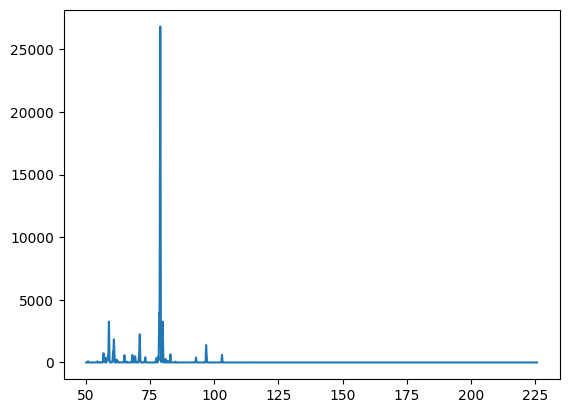

<Figure size 640x480 with 0 Axes>

Text(0.5, 0, 'm/z')

Text(0, 0.5, 'Intensity')

Text(0.5, 1.0, 'Spectrum with Axis Drift and Space Charge Simulation')

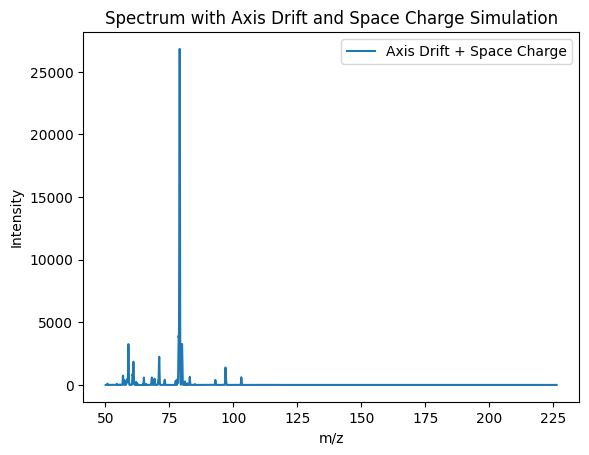

Text(0.5, 1.0, 'CWT RGB Image')

(-0.5, 223.5, 223.5, -0.5)

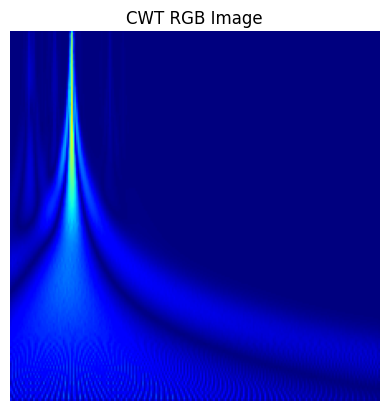

Text(0.5, 1.0, 'CWT RGB Image')

(-0.5, 223.5, 223.5, -0.5)

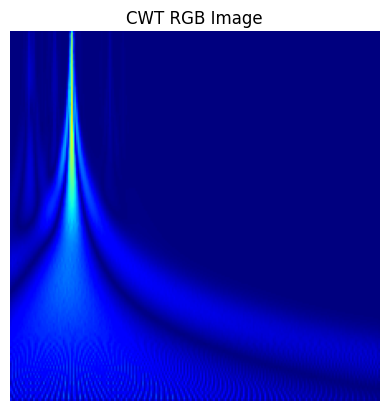

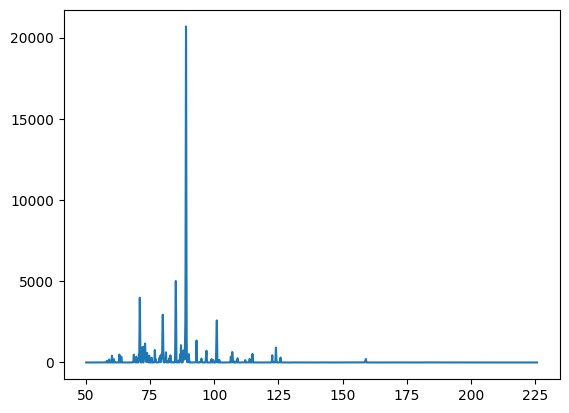

<Figure size 640x480 with 0 Axes>

Text(0.5, 0, 'm/z')

Text(0, 0.5, 'Intensity')

Text(0.5, 1.0, 'Spectrum with Axis Drift and Space Charge Simulation')

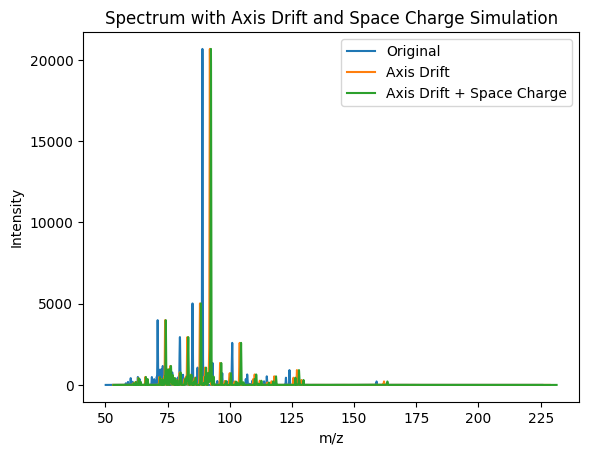

Text(0.5, 1.0, 'CWT RGB Image')

(-0.5, 223.5, 223.5, -0.5)

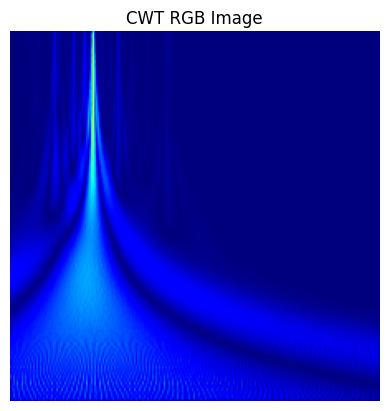

Text(0.5, 1.0, 'CWT RGB Image')

(-0.5, 223.5, 223.5, -0.5)

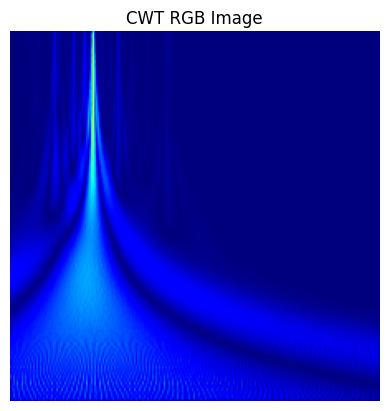

In [31]:

name1="E:/神经胶质瘤/HS_data_new/133/NMS2R1.mrz"
data1 = load_mrz(name1)
#     print(len(data['analysis']['scan_list'][0]['raw_data']))
data1 =process_mrz_data(data1, use_new_filter=2)
dot_len = np.size(data1['analysis']['scan_list'][0]['mz'])
y_int1=data1['analysis']['scan_list'][0]['analog_filtered'][0]
x_mz1=data1['analysis']['scan_list'][0]['mz'][0]
x_mz1 = np.array(x_mz1)
y_int1 = np.array(y_int1)
print(type(x_mz1))
plt.plot(x_mz1,y_int1)
#plt.savefig('plot22.svg', format='svg')
plt.show()

# 对原始数据进行轴漂移模拟
x_mz_drifted, y_int_drifted = simulate_axis_drift(x_mz1, y_int1, mz_shift=3)

# 再对漂移后的数据进行空间电荷模拟（或直接对原始数据模拟）
x_mz1_space, y_int1_space = simulate_space_charge(x_mz1, y_int1, alpha=1e-5)

# 可视化对比
plt.figure()
# plt.plot(x_mz1, y_int1, label='Original')
# plt.plot(x_mz_drifted, y_int_drifted, label='Axis Drift')
plt.plot(x_mz1_space, y_int1_space, label='Axis Drift + Space Charge')
plt.xlabel('m/z')
plt.ylabel('Intensity')
plt.title('Spectrum with Axis Drift and Space Charge Simulation')
plt.legend()
plt.show()


# 假设原始拉曼光谱数据存储在数组raw_signal中（长度可能不是1000）
raw_signal1 = y_int1  # 假定有5000点的原始数据
processed_signal1 = preprocess_signal(raw_signal1, target_length=1500)

# 参数根据给定表格（只是示例）
fs = 128
voices_per_octave = 12
p2, gamma = (60, 3)  # Morse小波参数（在此仅占位）

rgb_img1 = generate_cwt_rgb_image(processed_signal1, fs=fs, voices_per_octave=voices_per_octave, 
                                 wavelet_params=(p2,gamma), output_size=(224,224))

plt.imshow(rgb_img1)
plt.title('CWT RGB Image')
plt.axis('off')
plt.show()



# 假设原始拉曼光谱数据存储在数组raw_signal中（长度可能不是1000）
signal1 = y_int1_space  # 假定有5000点的原始数据
processed_signal_space1 = preprocess_signal(signal1, target_length=1500)

# 参数根据给定表格（只是示例）
fs = 128
voices_per_octave = 12
p2, gamma = (60, 3)  # Morse小波参数（在此仅占位）

rgb_img1_space = generate_cwt_rgb_image(processed_signal_space1 , fs=fs, voices_per_octave=voices_per_octave, 
                                 wavelet_params=(p2,gamma), output_size=(224,224))

plt.imshow(rgb_img1_space)
plt.title('CWT RGB Image')
plt.axis('off')
plt.show()


#########################################

name2="E:/神经胶质瘤/HS_data_new/133/NMS2R2.mrz"
data2 = load_mrz(name2)
#     print(len(data['analysis']['scan_list'][0]['raw_data']))
data2 =process_mrz_data(data2, use_new_filter=2)
dot_len = np.size(data2['analysis']['scan_list'][0]['mz'])
y_int2=data2['analysis']['scan_list'][0]['analog_filtered'][0]
x_mz2=data2['analysis']['scan_list'][0]['mz'][0]
x_mz2 = np.array(x_mz2)
y_int2 = np.array(y_int2)


plt.plot(x_mz2,y_int2)
#plt.savefig('plot22.svg', format='svg')
plt.show()

# 对原始数据进行轴漂移模拟
x_mz_drifted, y_int_drifted = simulate_axis_drift(x_mz2, y_int2, mz_shift=3)

# 再对漂移后的数据进行空间电荷模拟（或直接对原始数据模拟）
x_mz2_space, y_int2_space = simulate_space_charge(x_mz_drifted, y_int_drifted, alpha=5e-5)

# 可视化对比
plt.figure()
plt.plot(x_mz2, y_int2 , label='Original')
plt.plot(x_mz_drifted, y_int_drifted, label='Axis Drift')
plt.plot(x_mz2_space, y_int2_space, label='Axis Drift + Space Charge')
plt.xlabel('m/z')
plt.ylabel('Intensity')
plt.title('Spectrum with Axis Drift and Space Charge Simulation')
plt.legend()
plt.show()


# 假设原始拉曼光谱数据存储在数组raw_signal中（长度可能不是1000）
raw_signal2 = y_int2  # 假定有5000点的原始数据
processed_signal2 = preprocess_signal(raw_signal2, target_length=1500)

# 参数根据给定表格（只是示例）
fs = 128
voices_per_octave = 12
p2, gamma = (60, 3)  # Morse小波参数（在此仅占位）

rgb_img2 = generate_cwt_rgb_image(processed_signal2, fs=fs, voices_per_octave=voices_per_octave, 
                                 wavelet_params=(p2,gamma), output_size=(224,224))

plt.imshow(rgb_img2)
plt.title('CWT RGB Image')
plt.axis('off')
plt.show()


# 假设原始拉曼光谱数据存储在数组raw_signal中（长度可能不是1000）
signal2 = y_int2_space  # 假定有5000点的原始数据
processed_signal_space2 = preprocess_signal(signal2, target_length=1500)

# 参数根据给定表格（只是示例）
fs = 128
voices_per_octave = 12
p2, gamma = (60, 3)  # Morse小波参数（在此仅占位）

rgb_img2_space = generate_cwt_rgb_image(processed_signal_space2 , fs=fs, voices_per_octave=voices_per_octave, 
                                 wavelet_params=(p2,gamma), output_size=(224,224))

plt.imshow(rgb_img2_space)
plt.title('CWT RGB Image')
plt.axis('off')
plt.show()



In [13]:
import numpy as np
import cv2
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import Model

def mse(imageA, imageB):
    # 均方误差
    err = np.mean((imageA - imageB) ** 2)
    return err

def psnr(imageA, imageB):
    # 峰值信噪比，根据MSE计算
    mse_val = mse(imageA, imageB)
    if mse_val == 0:
        return float('inf')
    PIXEL_MAX = 1.0  # 如果图像范围是[0,1]
    return 20 * np.log10(PIXEL_MAX / np.sqrt(mse_val))

def compare_images_basic_metrics(img1, img2):
    # 假设img1, img2均为归一化到[0,1]的浮点图像，大小相同 (H,W,3)
    # 将其转换成灰度以计算SSIM
    img1_gray = cv2.cvtColor((img1*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    img2_gray = cv2.cvtColor((img2*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)

    mse_val = mse(img1_gray/255.0, img2_gray/255.0)
    psnr_val = psnr(img1_gray/255.0, img2_gray/255.0)
    ssim_val = ssim(img1_gray, img2_gray)

    return mse_val, psnr_val, ssim_val

def compare_images_feature_space(img1, img2):
    # 使用VGG16的特征层（如block4_pool的输出）作为特征提取器
    # 首先确保img1,img2为[0,1]范围，并resize到VGG16输入大小(224,224)
    img1_resized = cv2.resize((img1*255).astype(np.uint8),(224,224))
    img2_resized = cv2.resize((img2*255).astype(np.uint8),(224,224))

    img1_resized = img_to_array(img1_resized)
    img2_resized = img_to_array(img2_resized)

    img1_resized = np.expand_dims(img1_resized, axis=0)
    img2_resized = np.expand_dims(img2_resized, axis=0)

    img1_resized = preprocess_input(img1_resized.astype('float32'))
    img2_resized = preprocess_input(img2_resized.astype('float32'))

    # 加载VGG16模型，并截断到某一层作为特征提取器
    base_model = VGG16(weights='imagenet', include_top=False)
    # 在此使用block4_pool作为特征输出层
    feature_model = Model(inputs=base_model.input, outputs=base_model.get_layer('block4_pool').output)

    feat1 = feature_model.predict(img1_resized)
    feat2 = feature_model.predict(img2_resized)

    # 将特征向量展开为一维
    feat1_flat = feat1.flatten()
    feat2_flat = feat2.flatten()

    # 计算余弦相似度或欧氏距离来衡量特征空间相似性
    # 余弦相似度：cosine_sim = (feat1·feat2)/(||feat1||*||feat2||)
    cosine_sim = np.dot(feat1_flat, feat2_flat) / (np.linalg.norm(feat1_flat)*np.linalg.norm(feat2_flat))

    return cosine_sim


img1 =rgb_img1
img2 =rgb_img2

# 基本度量
mse_val, psnr_val, ssim_val = compare_images_basic_metrics(img1, img2)
print("MSE:", mse_val)
print("PSNR:", psnr_val)
print("SSIM:", ssim_val)

# 特征空间相似度
cosine_sim = compare_images_feature_space(img1, img2)
print("Feature Space Cosine Similarity:", cosine_sim)


MSE: 0.009648833185234879
PSNR: 20.155252018740597
SSIM: 0.7904519510105927
1/1 [==============================] - 0s 134ms/step
Feature Space Cosine Similarity: 0.80222625


In [14]:
img1 =rgb_img2
img2 =rgb_img2_space

# 基本度量
mse_val, psnr_val, ssim_val = compare_images_basic_metrics(img1, img2)
print("MSE:", mse_val)
print("PSNR:", psnr_val)
print("SSIM:", ssim_val)

# 特征空间相似度
cosine_sim = compare_images_feature_space(img1, img2)
print("Feature Space Cosine Similarity:", cosine_sim)

MSE: 0.0
PSNR: inf
SSIM: 1.0
1/1 [==============================] - 0s 127ms/step
Feature Space Cosine Similarity: 1.0


In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import Model
from sklearn.cluster import KMeans

def extract_features(img, target_size=(224,224)):
    """
    使用VGG16提取图像特征。
    img: (H,W,3)数组, [0,1]浮点数表示像素值
    """
    # Resize到VGG16输入尺寸
    img_resized = cv2.resize((img*255).astype(np.uint8), target_size)
    img_resized = img_to_array(img_resized)
    img_resized = np.expand_dims(img_resized, axis=0)
    img_resized = preprocess_input(img_resized.astype('float32'))

    # 使用VGG16的中间层作为特征输出层（如block4_pool）
    base_model = VGG16(weights='imagenet', include_top=False)
    feature_model = Model(inputs=base_model.input, outputs=base_model.get_layer('block4_pool').output)

    features = feature_model.predict(img_resized)
    features_flat = features.flatten()
    return features_flat


In [18]:

# 提取特征向量
f1 = extract_features(rgb_img1)
f2 = extract_features(rgb_img2)
f1_space = extract_features(rgb_img1_space)
f2_space = extract_features(rgb_img2_space)

print(f1)
# 将4个特征向量堆叠成 (4, feature_dim)
data = np.stack([f1, f2, f1_space, f2_space], axis=0)

# 使用KMeans对4张图像进行聚类，这里设定聚2类
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(data)

# labels是一个长度为4的一维数组，对应每张图像的类标签(0或1)
# 例如:
# image 0: rgb_img1 -> labels[0]
# image 1: rgb_img2 -> labels[1]
# image 2: rgb_img1_space -> labels[2]
# image 3: rgb_img2_space -> labels[3]

# 将结果打印出来
print("Clustering Results:")
print("rgb_img1 is in cluster:", labels[0])
print("rgb_img2 is in cluster:", labels[1])
print("rgb_img1_space is in cluster:", labels[2])
print("rgb_img2_space is in cluster:", labels[3])

1/1 [==============================] - 0s 236ms/step
[164.37688    0.       211.81735  ...  13.514017   0.         0.      ]
Clustering Results:
rgb_img1 is in cluster: 1
rgb_img2 is in cluster: 0
rgb_img1_space is in cluster: 1
rgb_img2_space is in cluster: 0


D:\Software\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
D:\Software\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


1/1 [==============================] - 0s 234ms/step
f1 shape: (100352,)


Text(0.5, 1.0, 'Features from rgb_img1')

Text(0.5, 1.0, 'Features from rgb_img2')

Text(0.5, 1.0, 'Features from rgb_img1_space')

Text(0.5, 1.0, 'Features from rgb_img2_space')

(-0.5, 255.5, 255.5, -0.5)

(-0.5, 255.5, 255.5, -0.5)

(-0.5, 255.5, 255.5, -0.5)

(-0.5, 255.5, 255.5, -0.5)

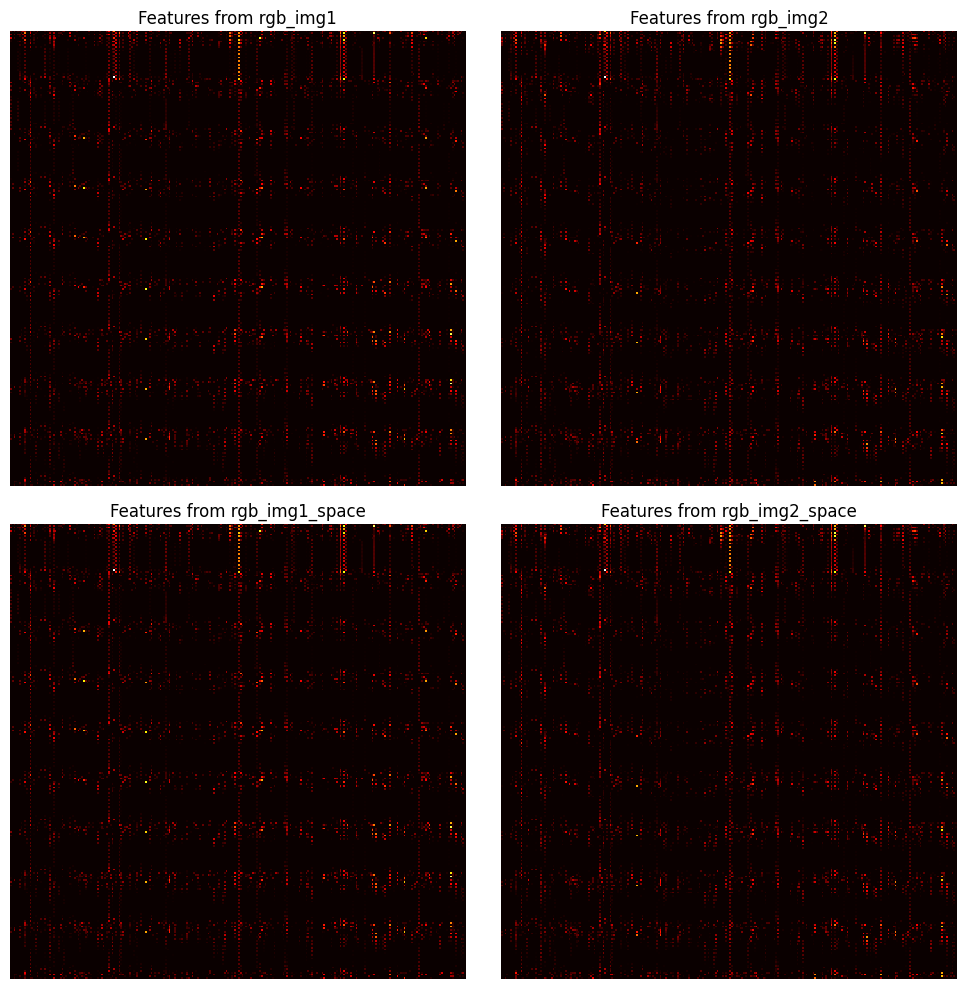

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# 假设从提取的特征函数返回的特征向量
f1 = extract_features(rgb_img1)  # 示例: (100352,)
f2 = extract_features(rgb_img2)
f1_space = extract_features(rgb_img1_space)
f2_space = extract_features(rgb_img2_space)

# 检查特征的大小
print(f"f1 shape: {f1.shape}")

# 选择适当的尺寸进行重塑
# 假设我们选择 256x256 或者 512x512，如果特征向量长度为100352
# 这里我们选择 256x256，因为它的大小为 65536，适合调整大小

image_size = 256  # 可以选择更合适的尺寸
f1_image = f1[:image_size**2].reshape(image_size, image_size)  # 使用前 65536 个元素
f2_image = f2[:image_size**2].reshape(image_size, image_size)
f1_space_image = f1_space[:image_size**2].reshape(image_size, image_size)
f2_space_image = f2_space[:image_size**2].reshape(image_size, image_size)

# 可视化
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(f1_image, cmap='hot', interpolation='nearest')
axes[0, 0].set_title("Features from rgb_img1")
axes[0, 1].imshow(f2_image, cmap='hot', interpolation='nearest')
axes[0, 1].set_title("Features from rgb_img2")
axes[1, 0].imshow(f1_space_image, cmap='hot', interpolation='nearest')
axes[1, 0].set_title("Features from rgb_img1_space")
axes[1, 1].imshow(f2_space_image, cmap='hot', interpolation='nearest')
axes[1, 1].set_title("Features from rgb_img2_space")

# 去除坐标轴
for ax in axes.flatten():
    ax.axis('off')

plt.tight_layout()
plt.show()


D:\Software\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
D:\Software\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


<Figure size 800x600 with 0 Axes>

Text(9719.529296875, 0.000988641520962119, 'Image 1')

Text(-9719.5283203125, 0.0009886418702080846, 'Image 2')

Text(9719.5283203125, 0.0009886418702080846, 'Image 3')

Text(-9719.5283203125, 0.000988641637377441, 'Image 4')

Text(0.5, 1.0, 'KMeans Clustering Results (2D Projection)')

Text(0.5, 0, 'PCA Component 1')

Text(0, 0.5, 'PCA Component 2')

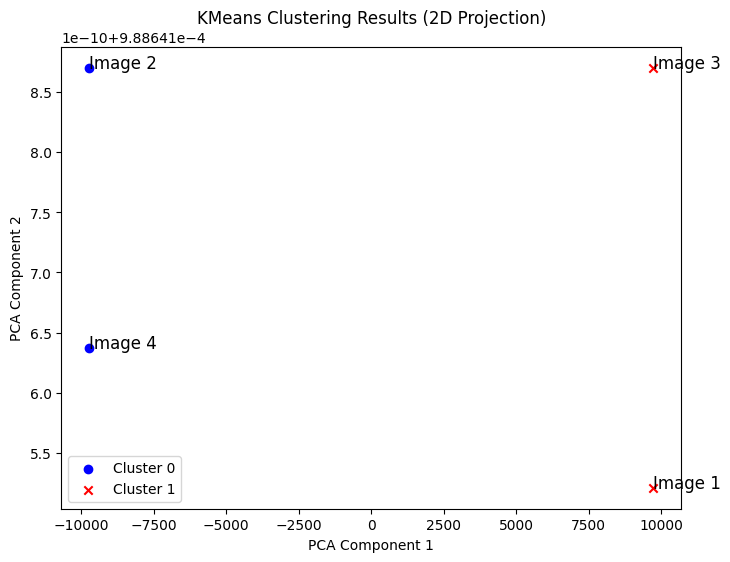

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 假设你已经有了4个特征向量 f1, f2, f1_space, f2_space 和它们的聚类标签
# 假设 f1, f2, f1_space, f2_space 是从 extract_features 函数中得到的特征向量

# 这里是之前的数据堆叠步骤
data = np.stack([f1, f2, f1_space, f2_space], axis=0)

# 使用PCA将特征向量降到二维
pca = PCA(n_components=2)
data_2d = pca.fit_transform(data)

# 使用KMeans对数据进行聚类
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(data)

# 绘制聚类结果
plt.figure(figsize=(8, 6))

# 为不同的类标签选择不同的颜色
plt.scatter(data_2d[labels == 0, 0], data_2d[labels == 0, 1], label='Cluster 0', color='b', marker='o')
plt.scatter(data_2d[labels == 1, 0], data_2d[labels == 1, 1], label='Cluster 1', color='r', marker='x')

# 标注每个点的对应图像
for i, label in enumerate(labels):
    plt.text(data_2d[i, 0], data_2d[i, 1], f'Image {i+1}', fontsize=12)

# 添加图例和标签
plt.title("KMeans Clustering Results (2D Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()

# 显示图形
plt.show()


## 暂时不用看

In [4]:
path = 'D:/DATA/ZHY/cwt图像处理/'
file_list = Method1_get_filelist(path)
path

'D:/DATA/ZHY/cwt图像处理/'

In [12]:
from scipy.linalg import expm,logm
for name in file_list:
    print(name)
    datastruct = load_mrz(name)
    print(datastruct['analysis']['scan_list'][1])
    data =process_mrz_data(datastruct, use_new_filter=2)
    dot_len = np.size(data['analysis']['scan_list'][0]['mz'],1)
    raw = np.array(data['analysis']['scan_list'][0]['analog_filtered'])[0:]
    print(type(raw))
    #baseline = baseline_delete_method2(raw)
#     y = np.log(abs(raw))
#     y[np.isnan(y)]=0
    print(raw)
    
plt.plot(data['analysis']['scan_list'][1]['mz'][0],raw[0])
plt.show()

D:/DATA/ZHY/cwt图像处理/1ppb2.mrz
{'algorithms': {'arbitrary_peak_picking': {'name': 'arbitrary_peak_picking', 'parameters': {'flat_top_intensity_max': 1000000000, 'flat_top_width_threshold': 10, 'mass_bin_pts': 50, 'max_peaks_count': 1000, 'min_peak_height_absolute': 50000, 'min_peak_height_percent': 0, 'sn_mass_bin_pts': 50, 'sn_max_peaks_count': 10000, 'sn_max_top_count': 10000, 'sn_min_peak_height_absolute': 5000, 'sn_min_peak_height_percent': 0, 'sn_tail_min_count': 20, 'sn_tail_percent': 0.05, 'sn_threshold_internal': 3, 'sn_top_count': 40, 'top_count': 30}, 'type': 'peak_picking_max', 'version': '1.0.0'}, 'base_line_correction': {'name': 'base_line_correction', 'parameters': {'max_base_line_width': 2000, 'relative_pos': 0.1}, 'type': 'filter_base_line_correction', 'version': '1.0.0'}, 'noise_reduction': {'name': 'noise_reduction', 'parameters': {'baseline_shift': 'auto', 'filter_width': 20}, 'type': 'filter_noise_reduction', 'version': '1.0.0'}}, 'average': 1, 'compound_code': '', '

KeyError: 'raw_data'

In [112]:
type(spectrogram)
len(spectrogram[1])


numpy.ndarray

95000

<Figure size 1000x600 with 0 Axes>

Text(0.5, 0, 'Time')

Text(0, 0.5, 'Frequency')

Text(0.5, 1.0, 'Continuous Wavelet Transform Spectrogram')

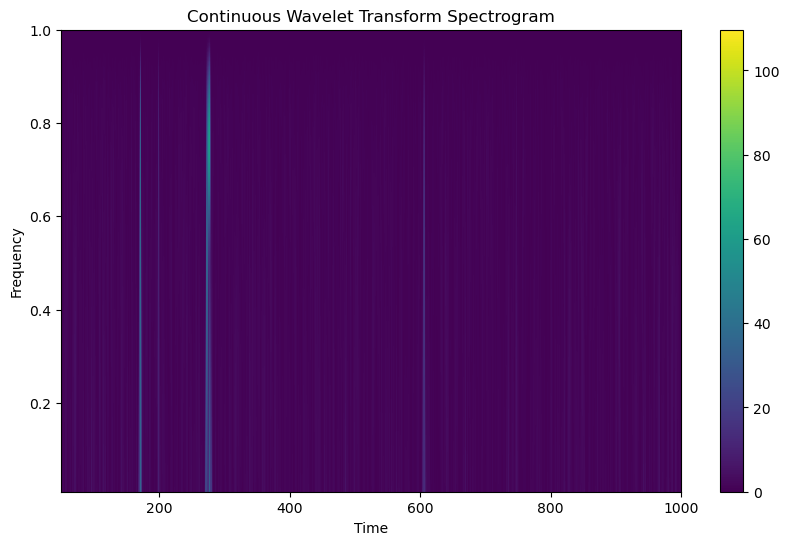

In [176]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal



# 信号强度
signal_strength = spectrogram[1]

# 连续小波变换参数
wavelet = signal.ricker
widths = np.arange(1, 101)  # 尺度范围

# 进行连续小波变换
cwt_matrix = signal.cwt(signal_strength, wavelet, widths)

# 获取时间轴和频率轴
time = spectrogram[0]
freq = 1 / widths[::-1]

# 绘制时频图
plt.figure(figsize=(10, 6))
plt.imshow(np.abs(cwt_matrix), extent=[time.min(), time.max(),freq.min(),freq.max()],  aspect='auto', vmin=abs(cwt_matrix).min(), vmax=abs(cwt_matrix).max())
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.title('Continuous Wavelet Transform Spectrogram')
plt.show()

In [ ]:
cwt_matrix

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import math


# 信号强度
signal_strength = spectrogram[1]

# 连续小波变换参数
wavelet = signal.ricker
widths = np.arange(1, 20000,50)  # 尺度范围

# 进行连续小波变换
cwt_matrix = signal.cwt(signal_strength, wavelet, widths)

# 获取时间轴和频率轴
time = spectrogram[0]
freq = 1 / widths[::-1]

# 绘制时频图
plt.figure(figsize=(10, 6))
plt.imshow(np.abs(cwt_matrix), extent=[time.min(), time.max(),10000,1],  aspect='auto', vmin=abs(cwt_matrix).min(), vmax=abs(cwt_matrix).max())
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.title('Continuous Wavelet Transform Spectrogram')
plt.show()

NameError: name 'spectrogram' is not defined

In [149]:
cwt_matrix.max()

127.57205914817864

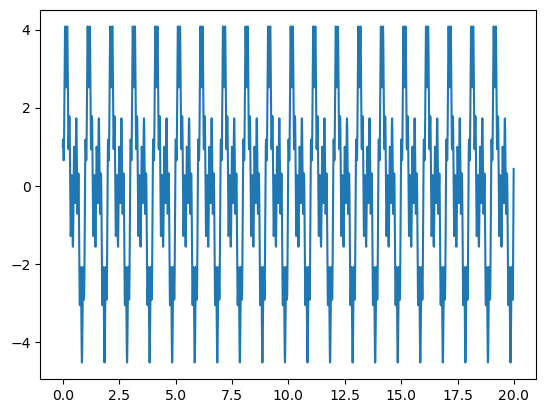

array([ 8.04450212,  8.51030782,  8.96133871, ..., -9.82084537,
       -9.40260011, -8.9655623 ])

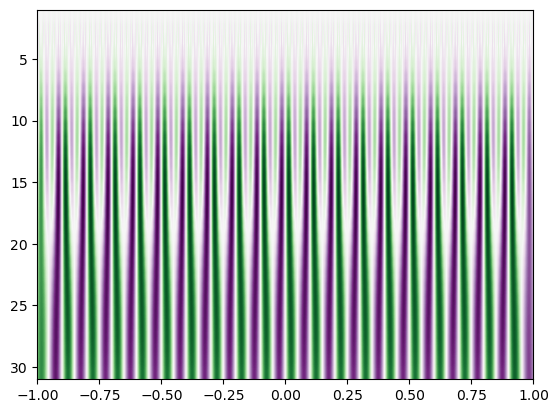

In [123]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(0, 20, 0.01)
y = np.sin(2 * np.pi * 1 * x) * 2 + np.sin(2 * np.pi * 2 * x) * 2  + np.cos(2 * np.pi * 10 * x)  

plt.plot(x, y)
plt.show()
from scipy import signal
widths = np.arange(1, 31)
cwtmatr = signal.cwt(y, signal.ricker, widths)
plt.imshow(cwtmatr, extent=[-1, 1, 31, 1], cmap='PRGn', aspect='auto',
vmax=abs(cwtmatr).max(), vmin=-abs(cwtmatr).max())
cwtmatr[29]

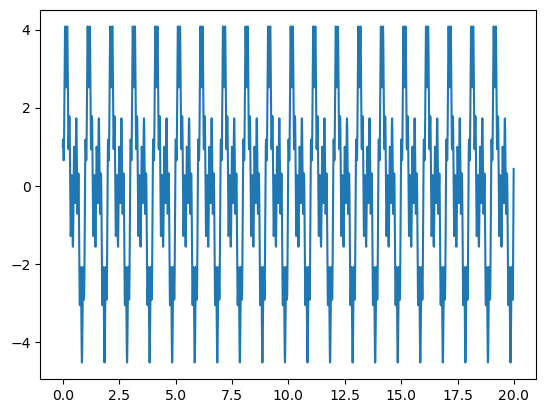

array([ 8.04450212,  8.51030782,  8.96133871, ..., -9.82084537,
       -9.40260011, -8.9655623 ])

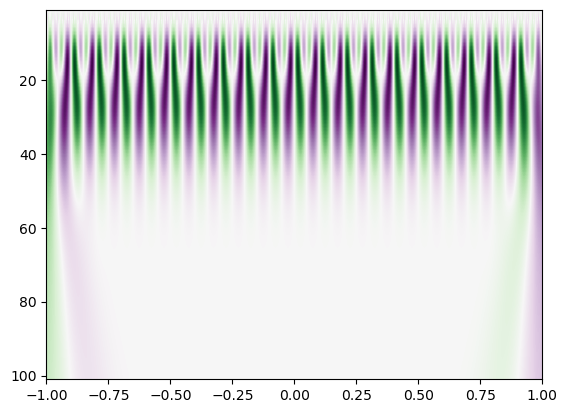

In [124]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(0, 20, 0.01)
y = np.sin(2 * np.pi * 1 * x) * 2 + np.sin(2 * np.pi * 2 * x) * 2  + np.cos(2 * np.pi * 10 * x)  

plt.plot(x, y)
plt.show()
from scipy import signal
widths = np.arange(1, 101)
cwtmatr = signal.cwt(y, signal.ricker, widths)
plt.imshow(cwtmatr, extent=[-1, 1,101, 1], cmap='PRGn', aspect='auto',
vmax=abs(cwtmatr).max(), vmin=-abs(cwtmatr).max())
cwtmatr[29]

In [85]:
img=np.random.rand(3,3)
img

array([[0.28766046, 0.38782549, 0.50954853],
       [0.23779755, 0.25497004, 0.3852558 ],
       [0.34379201, 0.3404012 , 0.41821852]])

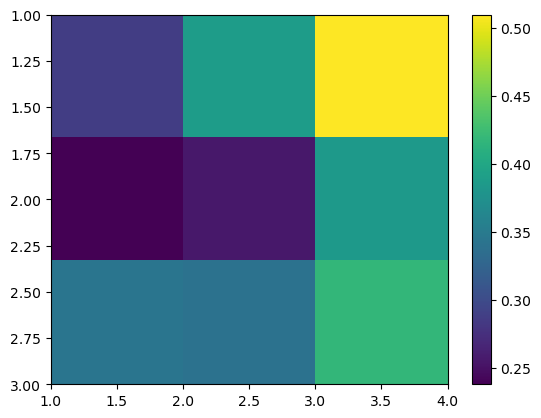

In [106]:
plt.imshow(img,extent=[1,4,3,1],aspect='auto',vmin=img.min(), vmax=img.max())
plt.colorbar()
plt.show()


In [187]:
max_value = np.max(img)
max_value
max_index = np.unravel_index(np.argmax(img),img.shape)
max_index

0.5095485318503238

(0, 2)

numpy.ndarray

100

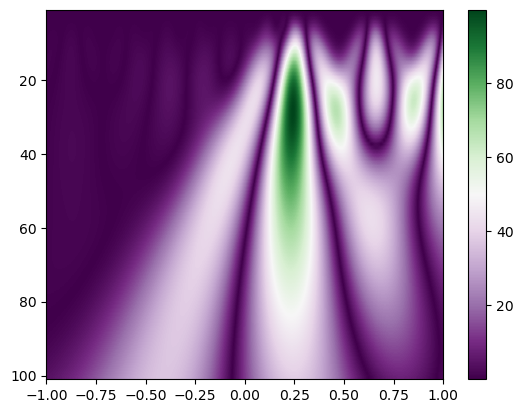

(array([27], dtype=int64), array([311], dtype=int64))

In [186]:
type(np.abs(cwt_matrix))
len(np.abs(cwt_matrix))
cwtmatr=np.abs(cwt_matrix)[:,22000:22500]
#np.abs(cwt_matrix)
plt.imshow(cwtmatr, extent=[-1, 1,101, 1], cmap='PRGn', aspect='auto',
vmin=abs(cwtmatr).min(), vmax=abs(cwtmatr).max())
plt.colorbar()
plt.show()
a=np.where(abs(cwtmatr)==abs(cwtmatr).max())
a

In [38]:
coeffs
np.max(coeffs)

array([[ 0.12297011, -4.06342288, -0.27425165, ...,  0.18170094,
        -0.2694235 , -4.06311462],
       [-0.17143748,  5.83618147, -5.64722441, ...,  2.11003365,
        -5.46680573,  5.83405606],
       [-0.44578567, 11.28103774, -0.06093737, ..., -7.16853992,
        -0.12466718, 11.28976293],
       [-0.25231747, 12.78387392,  8.69967435, ..., -4.68359652,
         8.53195993, 12.69162329],
       [-0.02949036, 12.57920515, 13.16398223, ...,  3.17871054,
        12.98949273, 12.7021008 ],
       [-0.26998808, 11.92662126, 15.79241433, ...,  9.35348498,
        15.41181469, 12.11486134]])

85.95261887531991

<Figure size 600x400 with 0 Axes>

TypeError: Invalid shape (6, 2, 1000) for image data

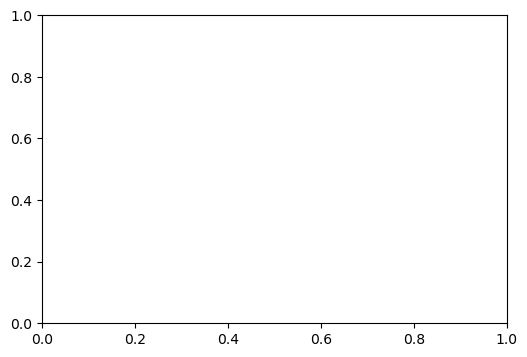

In [18]:
time_points = spectrogram.shape[1]

# 设置窗口大小和步长
window_size = 1000  # 窗口大小
step_size = 500  # 步长

# 进行连续小波变换并绘制时频图
wavelet = 'morl'
level = 6

# 存储每个窗口的时频图
spectrogram_windows = []

# 滑动窗口
for i in range(0, time_points - window_size + 1, step_size):
    # 获取当前窗口的数据
    window = spectrogram[:, i:i+window_size]

    # 进行连续小波变换
    coeffs, freqs = pywt.cwt(window, np.arange(1, level + 1), wavelet)

    # 获取时间轴和频率轴
    time = np.arange(window_size)
    freq = freqs[::-1]

    # 绘制时频图
    plt.figure(figsize=(6, 4))
    plt.imshow(coeffs, extent=[time.min(), time.max(), freq.min(), freq.max()], cmap='jet', aspect='auto')
    plt.colorbar()
    plt.xlabel('Time')
    plt.ylabel('Frequency')
    plt.title(f'Window: {i+1}-{i+window_size}')
    plt.savefig(f'window_{i+1}.png')  # 可选择保存每个窗口的时频图
    plt.close()

    # 将时频图添加到列表中
    spectrogram_windows.append(coeffs)

# 合并时频图
merged_spectrogram = np.concatenate(spectrogram_windows, axis=1)

# 绘制合并后的时频图
plt.figure(figsize=(10, 6))
plt.imshow(merged_spectrogram, extent=[0, time_points, freq.min(), freq.max()], cmap='jet', aspect='auto')
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.title('Merged Continuous Wavelet Transform Spectrogram')
plt.show()

In [17]:
# 定义小波函数
wavelet = 'morl'
level = 6  # 可根据需要调整级别

# 进行连续小波变换
coeffs, freqs = pywt.cwt(spectrogram, np.arange(1, level + 1), wavelet)
# 获取时间轴和频率轴
time = np.arange(spectrogram.shape[1])
freq = freqs[::-1]  # 频率轴需要反转

# 绘制时频图
plt.figure(figsize=(10, 6))
plt.imshow(coeffs, extent=[time.min(), time.max(), freq.min(), freq.max()], cmap='jet', aspect='auto')
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.title('Continuous Wavelet Transform Spectrogram')
plt.show()

<Figure size 1000x600 with 0 Axes>

RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

<Figure size 1000x600 with 0 Axes>

D:/DATA/ZHY/cwt图像处理/1ppb2.mrz
20
[[-2.25363050e-07 +6.88874813j  1.95482905e-01 -5.23084212j
  -3.83284300e-01 +2.27323069j ...  2.78882788e-01 +0.78302711j
  -3.75884854e-01 -2.54618314j  1.74783058e-01 +5.29672416j]
 [ 6.13970431e-01 +6.87514795j -2.56375085e-01 -5.14656379j
  -1.93559162e-01 +2.2226092j  ...  3.77942093e-01 +0.7921883j
  -6.01262644e-01 -2.58649689j  6.45565925e-01 +5.35664731j]
 [ 1.22506873e+00 +6.80748466j -4.77447717e-01 -5.09533014j
  -1.02402693e-01 +2.19415368j ...  4.58814097e-01 +0.79124273j
  -9.32483205e-01 -2.61555527j  1.11759300e+00 +5.37899422j]
 ...
 [ 2.58015250e-01+54.75340098j  2.78120153e+00+54.70791393j
   5.31730924e+00+54.52033714j ...  8.28507844e+00-55.22409874j
   5.80538568e+00-55.55135537j  3.30825369e+00-55.60533364j]
 [ 8.84156100e-01+63.25957479j  3.69068422e+00+63.15863137j
   6.31737801e+00+62.88231586j ...  7.59349662e+00-62.18097549j
   4.79850598e+00-62.67816036j  4.61527402e+00-62.75695069j]
 [ 1.16332593e+00+76.75969365j  4.6976

<Figure size 800x400 with 0 Axes>

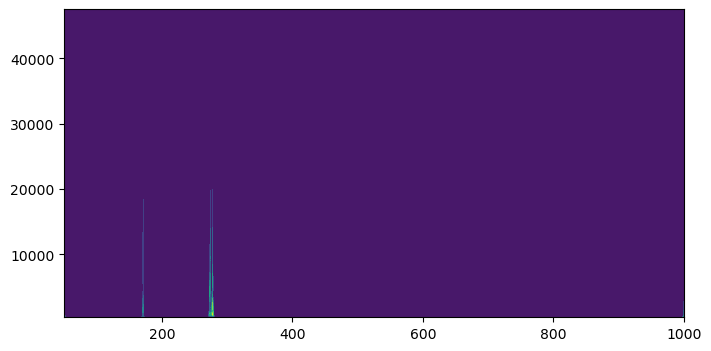

In [3]:
path = 'D:/DATA/ZHY/cwt图像处理/'
file_list = Method1_get_filelist(path)
for name in file_list:
    print(name)
    datastruct = load_mrz(name)
    print(len(datastruct['analysis']['scan_list']))
    data =process_mrz_data(datastruct, use_new_filter=2)

    dot_len = np.size(data['analysis']['scan_list'][1]['mz'],1)
    raw = np.array(data['analysis']['scan_list'][1]['raw_analog_data'])
    #baseline = baseline_delete_method2(raw)
#        print(baseline[0,:])
    wavename = 'cgau8'
    totalscal = 256
    # 中心频率
    fc = pywt.central_frequency(wavename)# 计算小波函数的中心频率
    cparam = 2 * fc * totalscal # 常数c
    scales = cparam / np.arange(totalscal, 1, -1)# 为使转换后的频率序列是一等差序列，尺度序列必须取为这一形式（也即小波尺度）
    [cwtmatr, frequencies] = pywt.cwt(raw[0,:], scales, wavename, 1.0 / 95000)
    print(cwtmatr)
    plt.figure(figsize=(8, 4))
    fig_raw=plt.contourf(np.array(data['analysis']['scan_list'][1]['mz'])[0,:], frequencies, abs(cwtmatr))

    #plt.gca().xaxis.set_major_locator(plt.NullLocator())
    #plt.gca().yaxis.set_major_locator(plt.NullLocator())
    plt.savefig('test_raw.jpg',pad_inches=0)

D:/DATA/ZHY/cwt图像处理/1ppb2.mrz
20
[[-0.01127337 +6.82188842j  0.20123239 -5.07699382j
  -0.38329057 +2.0706196j  ...  0.24101078 +0.56279325j
  -0.34578678 -2.05154501j  0.17632555 +4.73606239j]
 [ 0.59679429 +6.80698094j -0.23692862 -4.99077821j
  -0.21162478 +2.02039822j ...  0.31888412 +0.5648955j
  -0.52647817 -2.08991277j  0.59725487 +4.79837206j]
 [ 1.19857447 +6.73833333j -0.44397315 -4.93879553j
  -0.13844405 +1.99393311j ...  0.36587158 +0.56182726j
  -0.81322709 -2.11979704j  1.02884998 +4.82423047j]
 ...
 [-1.05744645+53.47058595j  1.34024197+53.44621963j
   3.56624877+53.21130726j ...  7.25520203-52.06263864j
   5.0389911 -52.35023797j  2.71556386-52.3669004j ]
 [-1.00649139+63.17163561j  1.85178548+62.87449767j
   4.72395421+62.95406171j ...  4.5732601 -61.34840723j
   2.03250433-61.4571036j   2.23306999-61.47550876j]
 [ 1.16780785+77.31064276j  4.46168625+76.78770943j
   4.7296215 +77.01405417j ...  6.88105772-75.74282999j
   3.84193784-76.11484446j  3.72038271-76.06600909

<Figure size 576x288 with 0 Axes>

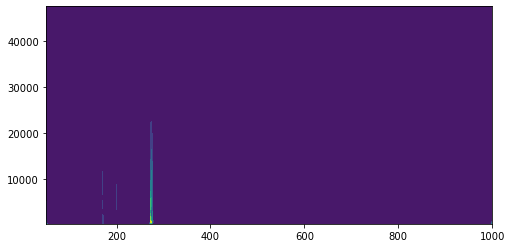

In [13]:
path = 'D:/DATA/ZHY/cwt图像处理/'
file_list = Method1_get_filelist(path)
for name in file_list:
    print(name)
    datastruct = load_mrz(name)
    print(len(datastruct['analysis']['scan_list']))
    data =process_mrz_data(datastruct, use_new_filter=2)

    dot_len = np.size(data['analysis']['scan_list'][2]['mz'],1)
    raw = np.array(data['analysis']['scan_list'][2]['raw_analog_data'])
    #baseline = baseline_delete_method2(raw)
#        print(baseline[0,:])
    wavename = 'cgau8'
    totalscal = 256
    # 中心频率
    fc = pywt.central_frequency(wavename)# 计算小波函数的中心频率
    cparam = 2 * fc * totalscal # 常数c
    scales = cparam / np.arange(totalscal, 1, -1)# 为使转换后的频率序列是一等差序列，尺度序列必须取为这一形式（也即小波尺度）
    [cwtmatr, frequencies] = pywt.cwt(raw[0,:], scales, wavename, 1.0 / 95000)
    print(cwtmatr)
    plt.figure(figsize=(8, 4))
    fig_raw2=plt.contourf(np.array(data['analysis']['scan_list'][2]['mz'])[0,:], frequencies, abs(cwtmatr))

    #plt.gca().xaxis.set_major_locator(plt.NullLocator())
    #plt.gca().yaxis.set_major_locator(plt.NullLocator())
    plt.savefig('test_raw2.jpg',pad_inches=0)

D:/DATA/ZHY/cwt图像处理/1ppb2.mrz
20
[[-3.45322903e-09+0.10555601j  2.99538981e-03-0.08015199j
  -5.86995990e-03+0.03483305j ...  1.91003655e-02+0.26796389j
   1.52904255e-03-0.30778549j -1.77049012e-02+0.14603403j]
 [ 9.40784443e-03+0.10534762j -3.92840883e-03-0.07886059j
  -2.96212793e-03+0.03405732j ...  4.36085179e-02+0.27101046j
  -2.62222185e-02-0.30433206j -5.48377982e-03+0.14109863j]
 [ 1.87716794e-02+0.10431082j -7.31589113e-03-0.07807553j
  -1.56422559e-03+0.03362114j ...  7.15875771e-02+0.27074537j
  -4.54812535e-02-0.30043669j -3.10419651e-03+0.13836832j]
 ...
 [ 2.58017026e-01+0.48786402j  3.65081917e-01+0.49566275j
   4.90264086e-01+0.46781609j ...  1.05748247e+00-1.43737088j
   9.78336973e-01-1.49883431j  8.92130527e-01-1.39308246j]
 [ 8.84158150e-01+0.59913006j  9.00789601e-01+0.55971575j
   7.43586373e-01+0.4678407j  ...  2.01970088e+00+0.23349968j
   2.00860726e+00-0.07924474j  1.82537530e+00-0.15803507j]
 [ 1.16332844e+00+0.01663533j  1.28078625e+00-0.05432615j
   1.0182

<Figure size 576x288 with 0 Axes>

95000

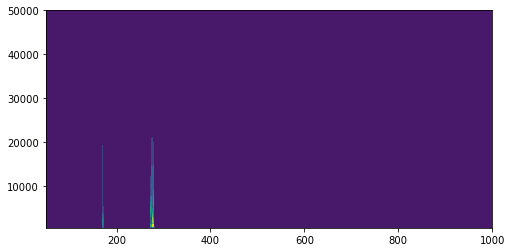

In [40]:
path = 'D:/DATA/ZHY/cwt图像处理/'
file_list = Method1_get_filelist(path)
for name in file_list:
    print(name)
    datastruct = load_mrz(name)
    print(len(datastruct['analysis']['scan_list']))
    data =process_mrz_data(datastruct, use_new_filter=2)

    dot_len = np.size(data['analysis']['scan_list'][1]['mz'],1)
    raw = np.array(data['analysis']['scan_list'][1]['raw_analog_data'])
    baseline = baseline_delete_method2(raw)
#        print(baseline[0,:])
    wavename = 'cgau8'
    totalscal = 256
    # 中心频率
    fc = pywt.central_frequency(wavename)# 计算小波函数的中心频率
    cparam = 2 * fc * totalscal # 常数c
    scales = cparam / np.arange(totalscal, 1, -1)# 为使转换后的频率序列是一等差序列，尺度序列必须取为这一形式（也即小波尺度）
    [cwtmatr, frequencies] = pywt.cwt(baseline[0,:], scales, wavename, 0.95 / 95000)
    print(cwtmatr)
    plt.figure(figsize=(8, 4))
    fig_baseline = plt.contourf(np.array(data['analysis']['scan_list'][1]['mz'])[0,:], frequencies, abs(cwtmatr))
    #plt.margins(0,0)        
    # 取消显示坐标轴
    #plt.gca().xaxis.set_major_locator(plt.NullLocator())
    #plt.gca().yaxis.set_major_locator(plt.NullLocator())
    plt.savefig('test_baseline.jpg',pad_inches=0)

dot_len  

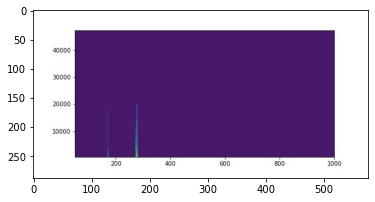

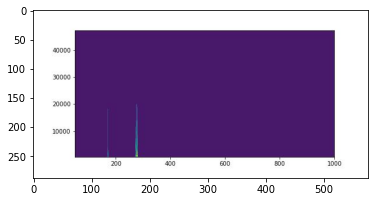

(288, 576, 3)

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [37]:
from PIL import Image 
import cv2
 
img_raw = cv2.imread("test_raw.jpg")

img_raw = cv2.cvtColor(img_raw, cv2.COLOR_BGR2RGB)
plt.imshow(img_raw)
plt.show()


img_baseline = cv2.imread("test_baseline.jpg")

img_baseline = cv2.cvtColor(img_baseline, cv2.COLOR_BGR2RGB)
plt.imshow(img_baseline)
plt.show()

image = Image.open("test_raw.jpg") # 用PIL中的Image.open打开图像
image_raw = np.array(image) # 转化成numpy数组
image = Image.open("test_baseline.jpg") # 用PIL中的Image.open打开图像
image_baseline = np.array(image) # 转化成numpy数组
image = Image.open("test_baseline800.jpg") # 用PIL中的Image.open打开图像
image_baseline800 = np.array(image) # 转化成numpy数组
image = Image.open("test_raw2.jpg") # 用PIL中的Image.open打开图像
image_raw2 = np.array(image) # 转化成numpy数组

image_baseline.shape
image_raw
image_raw2